# 專案介紹-預測違約機率

預測違約機率（Probability of Default, PD）或客戶信用風險時，最經典、被最廣泛使用的機器學習資料集主要可參考
Default of Credit Card Clients (UCI / Kaggle 經典信用卡違約資料集)
1. 來源與背景：由 I-Cheng Yeh 與 Che-hui Lien 收集，資料來自 2005年台灣的信用卡客戶。
2. 資料下載：https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset
3. 資料規模：共 30,000 筆實例、23～24 個變數（無遺漏值）。
4. 主要特徵：
• 個人基本資料：額度（LIMIT_BAL）、性別、教育程度、婚姻狀況、年齡。
• 歷史還款紀錄：前 6 個月（4月至9月）的繳款狀態。
• 帳單金額與還款金額：前 6 個月的每月帳單與實際繳款金額。
• 目標變數（Target）：下個月是否違約（default payment next month：1 代表違約，0 代表未違約）。

💡 建模時的常見挑戰與注意事項
1. 資料不平衡（Class Imbalance）：實際資料中「未違約」的客戶遠多於「違約」的客戶。訓練模型時常需要搭配重取樣（如 SMOTE）或調整成本敏感權重（Cost-sensitive learning）。
2. 模型選擇：實務與研究上，XGBoost、LightGBM、Random Forest 等樹狀模型，或是結合 XAI（可解釋性AI）來分析哪幾項特徵導致違約，通常比單純的邏輯回歸有更好的預測與解釋效果。
3. 機器學習模型比較：
• 常用來測試各種分類演算法，如羅吉斯迴歸（Logistic Regression）、隨機森林（Random Forest）、支援向量機（SVM）、梯度提升機（GBM / LightGBM）與類神經網路。
• 由於資料類別不平衡，評估指標通常不只看準確率（Accuracy），而會著重在 ROC-AUC、F1-Score、Precision-Recall Curve。

In [213]:
#載入基本套件
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
%matplotlib inline

In [310]:
#載入sklearn相關套件
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, ExtraTreesClassifier

In [217]:
#Data Source:https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset
df=pd.read_csv('FinalProject/UCI_Credit_Card.csv')
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [219]:
#檢視資料欄位及Index數值
for idx, name in enumerate(df.columns):
    print(f"Index {idx}: {name}")

Index 0: ID
Index 1: LIMIT_BAL
Index 2: SEX
Index 3: EDUCATION
Index 4: MARRIAGE
Index 5: AGE
Index 6: PAY_0
Index 7: PAY_2
Index 8: PAY_3
Index 9: PAY_4
Index 10: PAY_5
Index 11: PAY_6
Index 12: BILL_AMT1
Index 13: BILL_AMT2
Index 14: BILL_AMT3
Index 15: BILL_AMT4
Index 16: BILL_AMT5
Index 17: BILL_AMT6
Index 18: PAY_AMT1
Index 19: PAY_AMT2
Index 20: PAY_AMT3
Index 21: PAY_AMT4
Index 22: PAY_AMT5
Index 23: PAY_AMT6
Index 24: default.payment.next.month


資料欄位介紹
1. 個人基本屬性（Demographic）
• ID：客戶編號
• LIMIT_BAL：新台幣信用額度（包含個人與家庭附卡額度）
• SEX：性別（1 = 男性，2 = 女性）
• EDUCATION：教育程度（1 = 研究生，2 = 大學，3 = 高中，4 = 其他等）
• MARRIAGE：婚姻狀況（1 = 已婚，2 = 單身，3 = 其他）
• AGE：年齡（歲）
2. 過去還款紀錄（Repayment Status, 2005年4月–9月）
PAY_0 至 PAY_6：各月份的繳款狀態（PAY_0 為 9 月，PAY_2 為 8 月……以此類推）• 負數（如 -1 或 -2）通常代表按時全額繳款或超額/無消費
• 0 代表按最低應繳金額繳款
• 正數（1 至 9）代表延遲繳款的月數（例如 1 表示遲繳 1 個月，2 表示遲繳 2 個月）
3. 帳單金額（Bill Statement Amounts, 2005年4月–9月）
• BILL_AMT1 至 BILL_AMT6：各月份的信用卡帳單結算金額（新台幣）（BILL_AMT1 為 9 月帳單，BILL_AMT2 為 8 月帳單……）
4. 過去繳款金額（Previous Payment Amounts, 2005年4月–9月）
• PAY_AMT1 至 PAY_AMT6：各月份實際繳交的金額（新台幣）（對應前一個月的帳單繳費狀況）
5. 目標變數（Target）
• default.payment.next.month（或寫作 DEFAULT_PAYMENT_NEXT_MONTH）：次月是否違約（1 = 違約，0 = 未違約）

注意以下兩個Index在分析時要去除，所以只會剩下23個Index
Index 0: ID
Index 24: default.payment.next.month

In [221]:
print(f"原始特徵總數: {df.shape[1]}")

原始特徵總數: 25


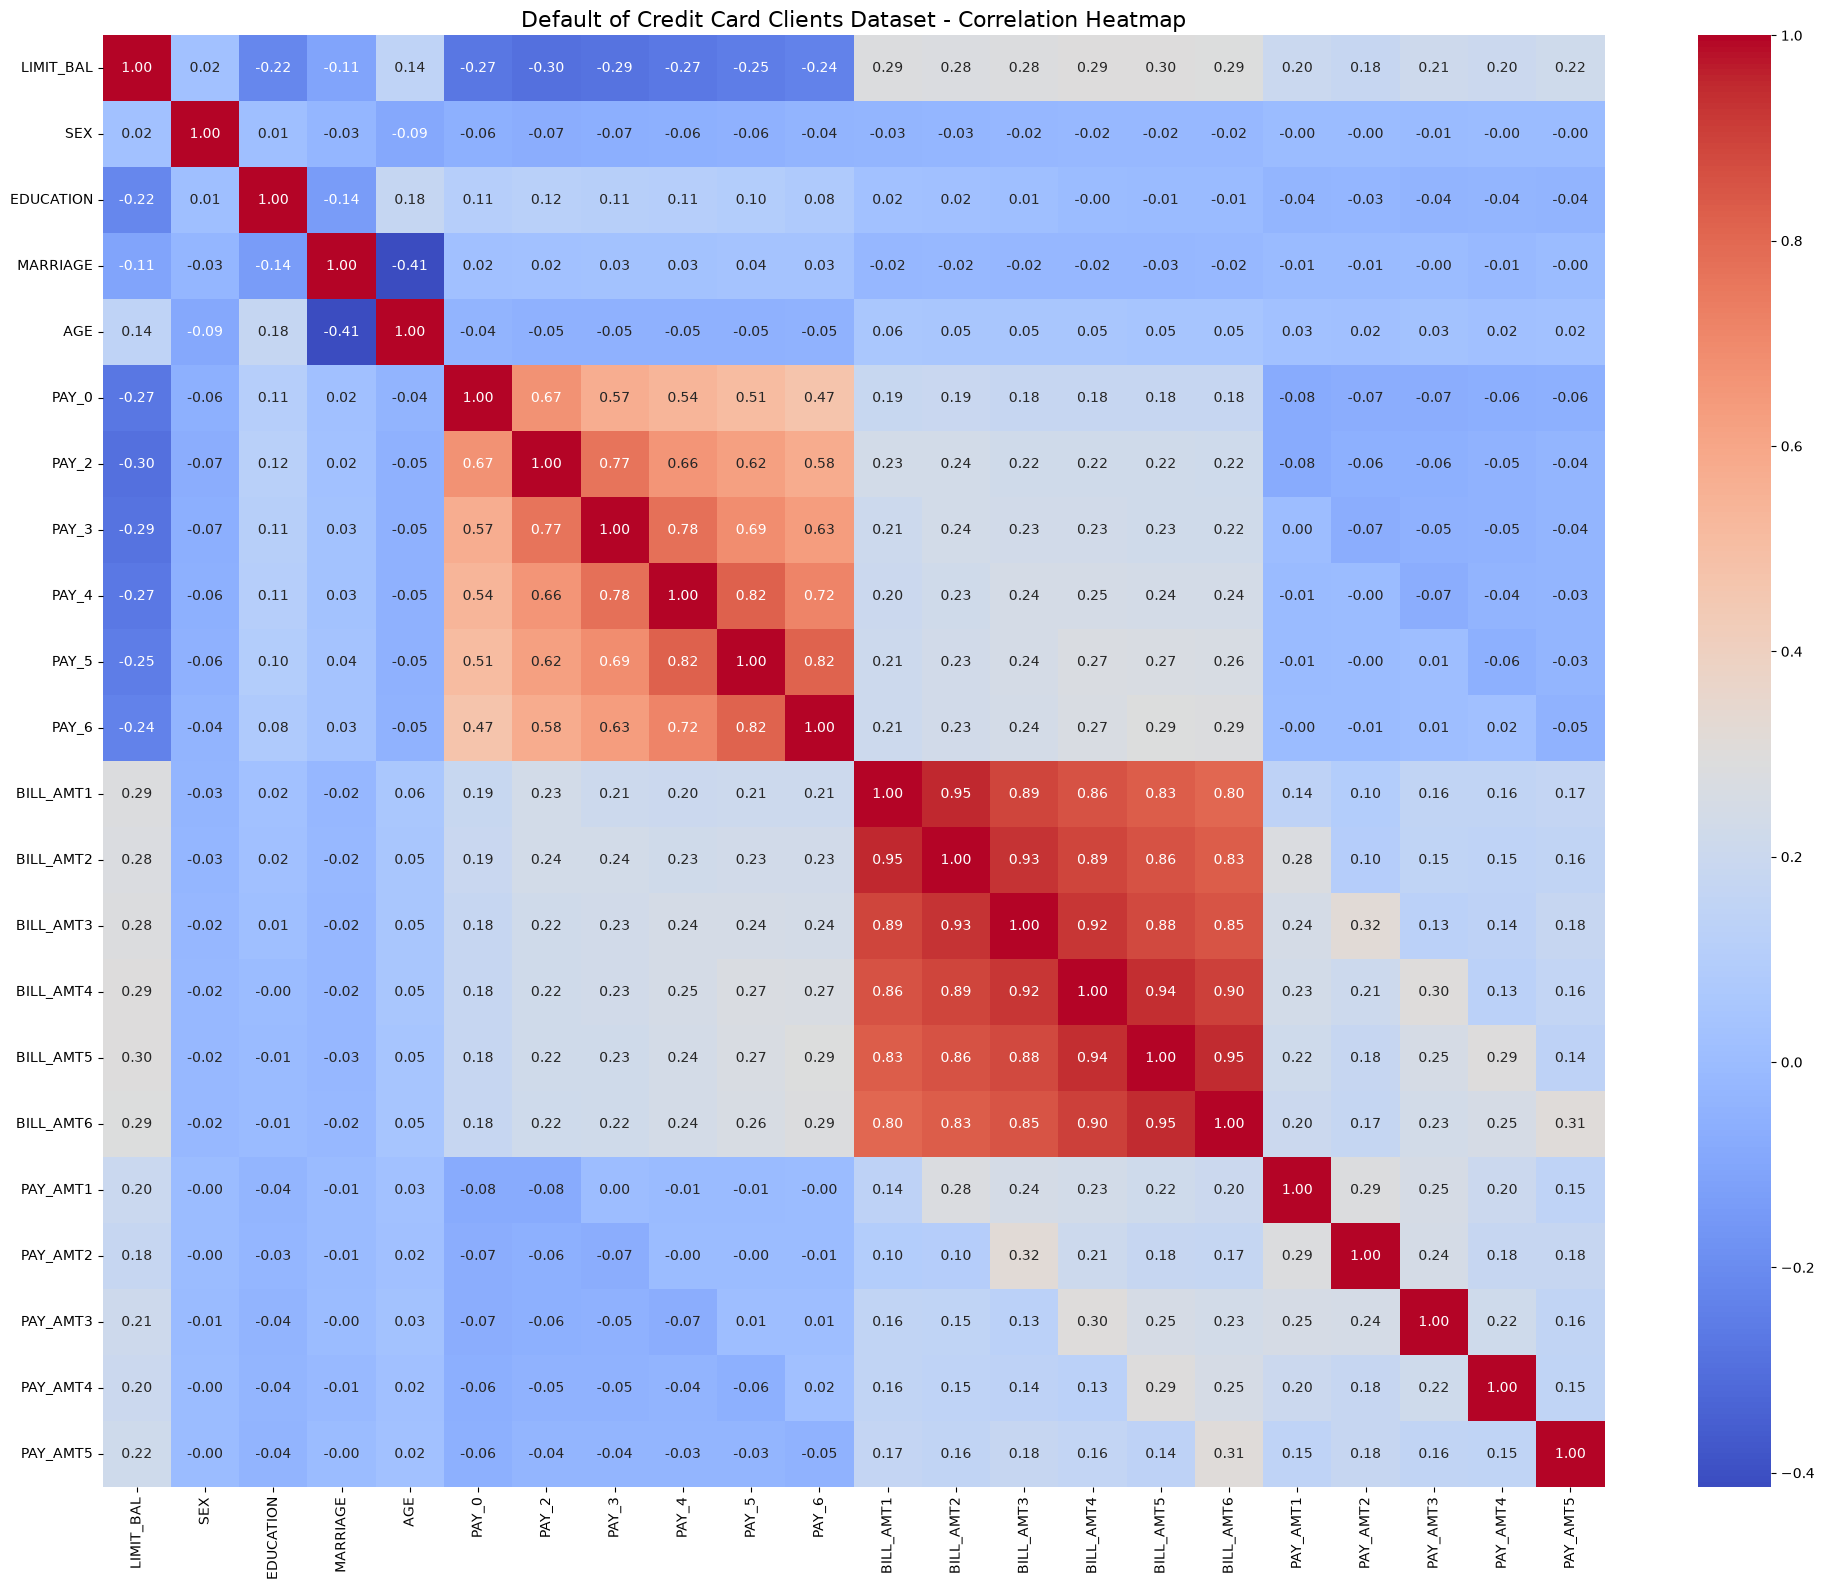

In [223]:
# -------------------------------------------------------------
# 繪製相關性熱圖 (Correlation Heatmap)
# -------------------------------------------------------------

plt.figure(figsize=(20, 16))
# 計算特徵間的相關係數矩陣
corr_matrix = df.iloc[:, 1:23].corr()

# 繪製 Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Default of Credit Card Clients Dataset - Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

經檢視確認，有幾個欄位數字有高度相關性，故需要作資料預處理。

In [225]:
# 1. 定義各組時間序列欄位（注意資料集中沒有 PAY_1）
pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [227]:
# 2. 帳單金額聚合 (6 -> 3)
df['BILL_MEAN_6M'] = df[bill_cols].mean(axis=1)#計算6個月的帳單金額平均數
df['BILL_MAX_6M'] = df[bill_cols].max(axis=1)#計算6個月的帳單金額最大值
df['BILL_TREND_3M'] = df[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3']].mean(axis=1) - \
                      df[['BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']].mean(axis=1)
                     #計算6個月的帳單金額趨勢

In [229]:
# 3. 繳款金額聚合 (6 -> 3)
df['PAY_MEAN_6M'] = df[pay_amt_cols].mean(axis=1)#計算6個月的繳款金額平均數
df['PAY_MAX_6M'] = df[pay_amt_cols].max(axis=1)#計算6個月的繳款金額最大值
df['PAY_TREND_3M'] = df[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3']].mean(axis=1) - \
                     df[['PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']].mean(axis=1)
                     #計算6個月的繳款金額趨勢

In [231]:
# 4. 還款狀態濃縮 (6 -> 4，保留 PAY_0 並新增 3 個統計特徵)
# 將大於 0 的遲繳狀態轉為布林值 (1=遲繳, 0=正常)
is_delayed = df[pay_status_cols] > 0

In [233]:
is_delayed

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
0,True,True,False,False,False,False
1,False,True,False,False,False,True
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
29995,False,False,False,False,False,False
29996,False,False,False,False,False,False
29997,True,True,True,False,False,False
29998,True,False,False,False,False,False


In [235]:
#過去半年總遲繳次數（DELAY_COUNT_6M）。 
#計算 6 個月中數值大於 0 的總次數（範圍 0 到 6），用來衡量客戶是否為習慣性遲繳的慣犯。
df['DELAY_COUNT_6M'] = is_delayed.sum(axis=1)
# 將小於 0 的正常還款狀態截斷為 0，再取最大值。此動作是只要留下未正常繳款的資料。
df['MAX_DELAY_6M'] = df[pay_status_cols].clip(lower=0).max(axis=1)
#計算「近 3 個月（7–9 月）的遲繳次數」減去「較早 3 個月（4–6 月）的遲繳次數」。數值大於 0 代表客戶的還款紀律正在近期快速惡化。
df['DELAY_TREND_3M'] = is_delayed[['PAY_0', 'PAY_2', 'PAY_3']].sum(axis=1) - \
                       is_delayed[['PAY_4', 'PAY_5', 'PAY_6']].sum(axis=1)

In [237]:
# 5. 移除已整併的 17 個原始時間序列欄位（保留 PAY_0）
cols_to_drop = bill_cols + pay_amt_cols + ['PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
df_final = df.drop(columns=cols_to_drop)

In [239]:
# 6.利用 pop() 把目標變數欄位(default.payment.next.month)抽出來，再直接指定回去，它就會自動排到最後面
df_final["default.payment.next.month"] = df_final.pop("default.payment.next.month")

In [241]:
print(f"特徵精簡完成！目前保留欄位總數（含ID與Target）：{df_final.shape[1]}")

特徵精簡完成！目前保留欄位總數（含ID與Target）：17


In [243]:
df_final.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,BILL_MEAN_6M,BILL_MAX_6M,BILL_TREND_3M,PAY_MEAN_6M,PAY_MAX_6M,PAY_TREND_3M,DELAY_COUNT_6M,MAX_DELAY_6M,DELAY_TREND_3M,default.payment.next.month
0,1,20000.0,2,2,1,24,2,1284.000000,3913.0,2568.000000,114.833333,689.0,229.666667,2,2,2,1
1,2,120000.0,2,2,2,26,-1,2846.166667,3455.0,-966.333333,833.333333,2000.0,-333.333333,2,2,0,1
2,3,90000.0,2,2,2,34,0,16942.166667,29239.0,3999.000000,1836.333333,5000.0,-994.000000,0,0,0,0
3,4,50000.0,2,2,1,37,0,38555.666667,49291.0,19231.333333,1398.000000,2019.0,683.333333,0,0,0,0
4,5,50000.0,1,2,1,57,-1,18223.166667,35835.0,-3031.666667,9841.500000,36681.0,12771.000000,0,0,0,0


## 先切分資料再標準化

In [245]:
#將資料分成訓練組及測試組
from sklearn.model_selection import train_test_split
X=df_final.drop(['ID','default.payment.next.month'],axis=1)
y=df_final['default.payment.next.month']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=101)

KNN、SVC 和 Logistic需要標準化。XGBoost、LightGBM、隨機森林這類樹模型只看數值的大小順序，不需要標準化。

In [247]:
#由於KNN分類法是藉由確認最近的觀察值來預測分類，因此變數的比例就會影響很大
#載入標準化比例尺(StandardScaler)套件，只將所有`特徵值`做標準化
Scaler=StandardScaler()
Scaler.fit(X_train_raw)# 訓練集：計算平均、標準差
X_train=pd.DataFrame(Scaler.transform(X_train_raw),columns=X.columns,index=X_train_raw.index)# 訓練集：轉換
X_test=pd.DataFrame(Scaler.transform(X_test_raw),columns=X.columns,index=X_test_raw.index)# 測試集：只轉換，不重新 fit
X_train.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,BILL_MEAN_6M,BILL_MAX_6M,BILL_TREND_3M,PAY_MEAN_6M,PAY_MAX_6M,PAY_TREND_3M,DELAY_COUNT_6M,MAX_DELAY_6M,DELAY_TREND_3M
20551,-0.906793,-1.238460,1.459155,0.857570,-0.812311,0.012612,-0.065315,-0.032863,0.629911,-0.376207,-0.359604,0.010283,-0.538759,-0.636743,-0.245096
17209,-0.598838,0.807454,-1.083757,0.857570,-0.812311,-0.875034,-0.661345,-0.671224,-0.209622,-0.247847,-0.208468,0.055024,-0.538759,-0.636743,-0.245096
2134,-0.059918,-1.238460,0.187699,-1.059323,3.307267,1.787903,0.410353,0.173919,-0.404731,-0.236665,-0.326052,-0.027014,3.294686,1.217287,-0.245096
2958,-1.137759,0.807454,0.187699,-1.059323,0.054968,0.900257,-0.712069,-0.772602,-0.279262,-0.507882,-0.413802,-0.048019,0.100149,0.290272,0.995894
716,-0.059918,0.807454,0.187699,0.857570,-0.920721,0.012612,0.596162,0.333449,-0.406214,-0.158948,-0.310567,-0.024680,-0.538759,-0.636743,-0.245096


In [251]:
X_test.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,BILL_MEAN_6M,BILL_MAX_6M,BILL_TREND_3M,PAY_MEAN_6M,PAY_MAX_6M,PAY_TREND_3M,DELAY_COUNT_6M,MAX_DELAY_6M,DELAY_TREND_3M
6015,-0.829804,0.807454,0.187699,-1.059323,1.464298,0.900257,-0.711675,-0.772284,-0.279262,-0.507882,-0.413802,-0.048019,0.100149,0.290272,0.995894
28660,-0.829804,0.807454,1.459155,0.857570,0.922248,0.012612,-0.001650,-0.020326,0.577329,-0.333415,-0.346699,-0.001340,-0.538759,-0.636743,-0.245096
12498,-0.906793,-1.238460,1.459155,-1.059323,1.355888,0.012612,-0.522029,-0.193054,0.389042,-0.404439,-0.351087,-0.045638,-0.538759,-0.636743,-0.245096
22957,-0.906793,0.807454,1.459155,-1.059323,1.355888,0.012612,-0.101025,-0.131942,0.276879,-0.246182,-0.284758,0.010329,-0.538759,-0.636743,-0.245096
14848,-0.290884,-1.238460,0.187699,0.857570,-0.920721,0.012612,1.018573,0.709403,-0.027156,-0.082928,-0.269841,-0.045942,-0.538759,-0.636743,-0.245096


In [253]:
#f確認驗證的資料沒有遺漏的數值
def get_nulls(training, testing):
    print("Training Data:")
    print(pd.isnull(training).sum())
    print("Testing Data:")
    print(pd.isnull(testing).sum())

get_nulls(X_train, X_test)

Training Data:
LIMIT_BAL         0
SEX               0
EDUCATION         0
MARRIAGE          0
AGE               0
PAY_0             0
BILL_MEAN_6M      0
BILL_MAX_6M       0
BILL_TREND_3M     0
PAY_MEAN_6M       0
PAY_MAX_6M        0
PAY_TREND_3M      0
DELAY_COUNT_6M    0
MAX_DELAY_6M      0
DELAY_TREND_3M    0
dtype: int64
Testing Data:
LIMIT_BAL         0
SEX               0
EDUCATION         0
MARRIAGE          0
AGE               0
PAY_0             0
BILL_MEAN_6M      0
BILL_MAX_6M       0
BILL_TREND_3M     0
PAY_MEAN_6M       0
PAY_MAX_6M        0
PAY_TREND_3M      0
DELAY_COUNT_6M    0
MAX_DELAY_6M      0
DELAY_TREND_3M    0
dtype: int64


## 建立邏輯迴歸模型 Logistic Regression Model 與訓練模型

In [255]:
#匯入在sklearn.linear_model套件裡面的LinearRegression模型
#將模型工具指派給一變數做使用
from sklearn.linear_model import LinearRegression
## 導入Sklearn中的線性模組
from sklearn import linear_model
regr = LinearRegression()

In [257]:
#建立訓練組邏輯迴歸模型
logmodel = LogisticRegression()
logmodel.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [259]:
#使用模型進行測試集資料的預測
predictions = logmodel.predict(X_test)
predictions2 = logmodel.predict(X_train)

In [261]:
#ground truth
print(y_test.values)
print(y_train.values)

[1 0 0 ... 0 1 0]
[0 0 1 ... 1 1 1]


In [263]:
error_index2=np.where(predictions2!=y_train.values)[0]
print('train accuracy:',1-len(error_index2)/len(X_train))
error_index=np.where(predictions!=y_test.values)[0]
print('test accuracy:',1-len(error_index)/len(X_test))

train accuracy: 0.8069166666666667
test accuracy: 0.8116666666666666


In [267]:
print('error_index:',error_index)
print('miss classification :',predictions[error_index])#錯誤答案
#【修正】error_index 是「測試集內的位置」，要先換成原始資料的 index，才對得到正確的客戶
data_index=X_test.index[error_index]
df_final.loc[data_index]#預測錯誤客戶的原始資料

error_index: [   0    8   10 ... 5990 5991 5998]
miss classification : [0 0 0 ... 0 0 0]


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,BILL_MEAN_6M,BILL_MAX_6M,BILL_TREND_3M,PAY_MEAN_6M,PAY_MAX_6M,PAY_TREND_3M,DELAY_COUNT_6M,MAX_DELAY_6M,DELAY_TREND_3M,default.payment.next.month
6015,6016,60000.0,2,2,1,49,1,0.000000,0.0,0.000000,0.000000,0.0,0.000000,1,1,1,1
8362,8363,50000.0,2,3,1,52,0,12185.833333,22916.0,-38.333333,3011.166667,14580.0,4801.666667,1,2,1,1
4831,4832,280000.0,1,1,1,42,0,125030.166667,173092.0,70037.000000,3581.833333,5853.0,1778.333333,0,0,0,1
12003,12004,30000.0,1,2,1,35,1,12511.000000,30821.0,-34750.666667,6136.833333,35821.0,11607.000000,3,3,-1,0
29830,29831,340000.0,1,1,2,33,1,0.000000,0.0,0.000000,0.000000,0.0,0.000000,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18489,18490,50000.0,2,2,2,26,2,23450.166667,48510.0,34379.000000,1473.500000,3041.0,919.666667,1,2,1,1
5793,5794,50000.0,1,2,1,48,1,18500.166667,19273.0,-1207.666667,799.666667,1829.0,485.333333,5,2,1,0
12516,12517,50000.0,2,3,2,50,0,33899.833333,50138.0,14407.666667,1421.666667,4130.0,643.333333,1,2,1,1
15306,15307,60000.0,2,2,1,34,-1,643.166667,2084.0,296.333333,200.000000,1200.0,-400.000000,4,2,0,1


In [297]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

y_pred = logmodel.predict(X_test)                # 分類結果（0/1），門檻 0.5
y_proba = logmodel.predict_proba(X_test)[:, 1]   # 違約 = 1 的機率

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
l_loss = log_loss(y_test, y_proba)               # Log Loss 要用機率，不能用 y_pred

print(f"Logistic Accuracy : {accuracy:.4f}")
print(f"Logistic Precision: {precision:.4f}")
print(f"Logistic Recall   : {recall:.4f}")
print(f"Logistic F1 Score : {f1:.4f}")
print(f"Logistic Log Loss : {l_loss:.4f}")

Logistic Accuracy : 0.8117
Logistic Precision: 0.6585
Logistic Recall   : 0.2855
Logistic F1 Score : 0.3983
Logistic Log Loss : 0.4457


## 建立K-Nearest Neighbors，K-近鄰演算法

In [269]:
#使用KNN演算法
from sklearn.neighbors import KNeighborsClassifier
#從k=1開始測試
knn=KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train,y_train)
pred=knn.predict(X_test)

In [271]:
#測試KNN演算法的好壞
from sklearn.metrics import classification_report,confusion_matrix
print(confusion_matrix(y_test,pred))

[[3873  817]
 [ 816  494]]


In [273]:
print(classification_report(y_test,pred))
#目標變數（Target） 次月是否違約（1 = 違約，0 = 未違約）

              precision    recall  f1-score   support

           0       0.83      0.83      0.83      4690
           1       0.38      0.38      0.38      1310

    accuracy                           0.73      6000
   macro avg       0.60      0.60      0.60      6000
weighted avg       0.73      0.73      0.73      6000



In [275]:
#剛剛只先用了k=1來建立模型，現在利用for來建立迴圈(選擇不同k值)，並紀錄錯誤率
error_rate = []

for i in range(1,40):
    knn_i=KNeighborsClassifier(n_neighbors=i)
    knn_i.fit(X_train,y_train)
    pred_i=knn_i.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error Rate')

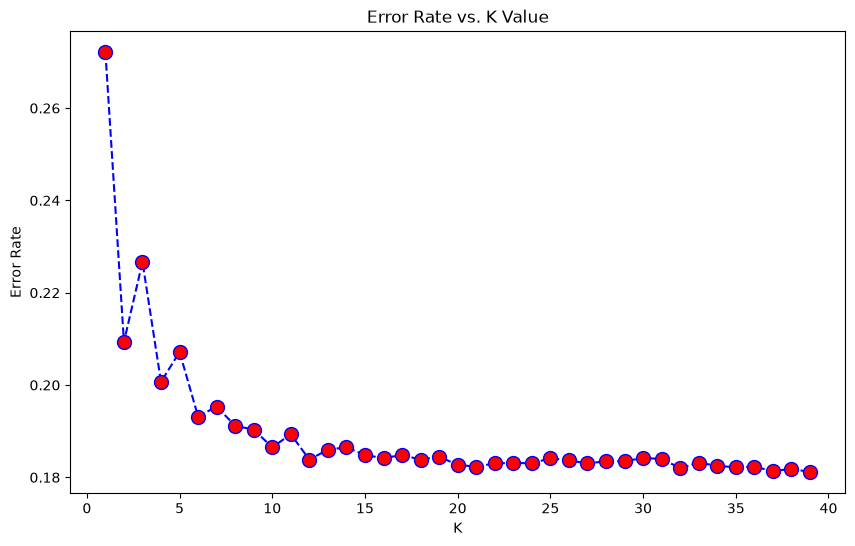

In [277]:
#將k=1~40的錯誤率製圖畫出。k=15之後，錯誤率就在18-19%之間震盪。
plt.figure(figsize=(10,6))
plt.plot(range(1,40),error_rate,color='blue',linestyle='dashed',marker='o',markerfacecolor='red',markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

In [200]:
#跟一開始k=1做比較
knn = KNeighborsClassifier(n_neighbors=1)

knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH k=1')
print('\n')
print(confusion_matrix(y_test,pred))
print('\n')
print(classification_report(y_test,pred))

WITH k=1


[[3881  809]
 [ 813  497]]


              precision    recall  f1-score   support

           0       0.83      0.83      0.83      4690
           1       0.38      0.38      0.38      1310

    accuracy                           0.73      6000
   macro avg       0.60      0.60      0.60      6000
weighted avg       0.73      0.73      0.73      6000



In [279]:
#選擇錯誤率最低的K=?來看precision、recall、f1-score、support表現
knn = KNeighborsClassifier(n_neighbors=39)

knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH k=39')
print('\n')
print(confusion_matrix(y_test,pred))
print('\n')
print(classification_report(y_test,pred))

WITH k=39


[[4487  203]
 [ 884  426]]


              precision    recall  f1-score   support

           0       0.84      0.96      0.89      4690
           1       0.68      0.33      0.44      1310

    accuracy                           0.82      6000
   macro avg       0.76      0.64      0.67      6000
weighted avg       0.80      0.82      0.79      6000



In [300]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=39)   # 用交叉驗證選出的 k；也可寫 best_k
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)                 # 分類結果（0/1）
y_proba = knn.predict_proba(X_test)[:, 1]    # 違約 = 1 的機率

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
l_loss = log_loss(y_test, y_proba)           # Log Loss 要用機率，不能用 y_pred

print(f"KNN Accuracy : {accuracy:.4f}")
print(f"KNN Precision: {precision:.4f}")
print(f"KNN Recall   : {recall:.4f}")
print(f"KNN F1 Score : {f1:.4f}")
print(f"KNN Log Loss : {l_loss:.4f}")

Accuracy : 0.8188
Precision: 0.6773
Recall   : 0.3252
F1 Score : 0.4394
Log Loss : 0.5070


## Simple Averaging Approach

In [281]:
LogReg_clf = LogisticRegression()
DTree_clf = DecisionTreeClassifier()
SVC_clf = SVC()

LogReg_clf.fit(X_train, y_train)
DTree_clf.fit(X_train, y_train)
SVC_clf.fit(X_train, y_train)

LogReg_pred = LogReg_clf.predict(X_test)
DTree_pred = DTree_clf.predict(X_test)
SVC_pred = SVC_clf.predict(X_test)

#【修正】原本的 (a+b+c)//3 要三個模型都預測 1 才會得到 1；多數決應為「至少兩票」
averaged_preds = ((LogReg_pred + DTree_pred + SVC_pred) >= 2).astype(int)
acc = accuracy_score(y_test, averaged_preds)
print(acc)

0.8201666666666667


## Voting Classification Example

In [303]:
# 取代 SVC(probability=True)：用內部交叉驗證將 SVC 的分數校準成機率
from sklearn.calibration import CalibratedClassifierCV
SVC_clf = CalibratedClassifierCV(SVC(random_state=101), ensemble=False)
DTree_clf = DecisionTreeClassifier(max_depth=5, random_state=101)
LogReg_clf = LogisticRegression()

voting_clf = VotingClassifier(
    estimators=[('SVC', SVC_clf), ('DTree', DTree_clf), ('LogReg', LogReg_clf)],
    voting='soft'
)
voting_clf.fit(X_train, y_train)

y_pred = voting_clf.predict(X_test)                # 分類結果（0/1）
y_proba = voting_clf.predict_proba(X_test)[:, 1]   # 違約 = 1 的機率

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
l_loss = log_loss(y_test, y_proba)                 # Log Loss 要用機率，不能用 y_pred

print(f"Soft voting Accuracy : {accuracy:.4f}")
print(f"Soft voting Precision: {precision:.4f}")
print(f"Soft voting Recall   : {recall:.4f}")
print(f"Soft voting F1 Score : {f1:.4f}")
print(f"Soft voting Log Loss : {l_loss:.4f}")

voting Accuracy : 0.8248
voting Precision: 0.7052
voting Recall   : 0.3397
voting F1 Score : 0.4585
voting Log Loss : 0.4316


# 總結

In [312]:
models = {
    'Logistic': LogisticRegression(),
    'KNN (k=39)': KNeighborsClassifier(n_neighbors=39),
    'Soft Voting': VotingClassifier(
        estimators=[('SVC', CalibratedClassifierCV(SVC(random_state=101), ensemble=False)),
                    ('DTree', DecisionTreeClassifier(max_depth=5, random_state=101)),
                    ('LogReg', LogisticRegression())],
        voting='soft'),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
        'Log Loss': log_loss(y_test, y_proba),
    })

comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(4))

# Log Loss 越低越好，其餘指標越高越好
best = comparison.drop(columns='Log Loss').idxmax()
best['Log Loss'] = comparison['Log Loss'].idxmin()
display(best.to_frame('Best Model'))

,Accuracy,Precision,Recall,F1,AUC,Log Loss
Model,,,,,,
Logistic,0.8117,0.6585,0.2855,0.3983,0.7437,0.4457
KNN (k=39),0.8188,0.6773,0.3252,0.4394,0.7470,0.5070
Soft Voting,0.8248,0.7052,0.3397,0.4585,0.7679,0.4316


,Best Model
Accuracy,Soft Voting
Precision,Soft Voting
Recall,Soft Voting
F1,Soft Voting
AUC,Soft Voting
Log Loss,Soft Voting
